# ECG-FM — inference and XAI prototype

[ECG-FM](https://arxiv.org/abs/2408.05178)

## 1. Check the runtime

A GPU is recommended. This cell is informational; it does not install or train anything.

In [1]:
import os, sys, platform, subprocess
import torch

print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using:', DEVICE)

Python: 3.13.15
PyTorch: 2.11.0+cpu
CUDA available: False
Using: cpu


## 2. Install the ECG-FM framework and helper packages

ECG-FM uses the `fairseq-signals` framework, not Hugging Face `transformers`. Install it directly from the maintained source. The editable install is intentional: it exposes the project modules and commands. If Colab's base PyTorch changes and this cell fails, restart the runtime, inspect the error, and use the troubleshooting cell below before changing versions.

In [2]:
# Core framework. The clone guard also makes this cell safe to re-run in one runtime.
!test -d /content/fairseq-signals/.git || git clone --depth 1 https://github.com/Jwoo5/fairseq-signals.git /content/fairseq-signals
%cd /content/fairseq-signals
!python -m pip install --upgrade pip
!python -m pip install -e .

# Packages used by this notebook. ecg-transform is used by the official quickstart.
!python -m pip install 'huggingface_hub>=0.24' 'ecg-transform==0.1.3' wfdb scipy pandas matplotlib captum
%cd /content

Cloning into '/content/fairseq-signals'...
remote: Enumerating objects: 312, done.
remote: Counting objects: 100% (312/312), done.
remote: Compressing objects: 100% (259/259), done.
remote: Total 312 (delta 70), reused 178 (delta 27), pack-reused 0 (from 0)
Receiving objects: 100% (312/312), 1.26 MiB | 4.82 MiB/s, done.
Resolving deltas: 100% (70/70), done.
/content/fairseq-signals
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 11.9 MB/s eta 0:00:00
  Attempting uninstall: pip
    Found existing installation: pip 24.1.2
    Uninstalling pip-24.1.2:
      Successfully uninstalled pip-24.1.2
Obtaining file:///content/fairseq-signals
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fairseq_signals (pyproject.toml) ... done
  Created wheel for fairseq_signals:

### Optional troubleshooting for dependency drift

Do not run this pre-emptively. First restart the Colab runtime and retry the previous cell. If a current Colab image has a dependency conflict, record the output with the next cell and consult the framework repository's requirements/issues. Pinning a different PyTorch version without matching the Colab CUDA runtime can make GPU unavailable.

In [3]:
# Diagnostic only — run if installation/imports fail.
!python -m pip check
!python -m pip show torch fairseq-signals ecg-transform | sed -n '1,120p'

ipython 7.34.0 requires jedi, which is not installed.
Name: torch
Version: 2.11.0+cpu
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License: BSD-3-Clause
Location: /usr/local/lib/python3.13/dist-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: accelerate, captum, fairseq_signals, fastai, peft, sentence-transformers, timm, torchdata, torchvision
---
Name: fairseq_signals
Version: 1.0.0a0+f8f0ff1
Summary: Facebook AI Research Sequence-to-Sequence Toolkit modifed for ecg signals
Home-page: 
Author: 
Author-email: 
License: 
Location: /usr/local/lib/python3.13/dist-packages
Editable project location: /content/fairseq-signals
Requires: cffi, cython, hydra-core, numpy, omegaconf, regex, sacrebleu, scikit-learn, torch, tqdm, transformers, wfdb
Required-by: 
---
Name: ecg-transform
Version: 0.1.3
Summary: Package

## 3. Download the released ECG-FM checkpoint

The model card hosts weights only. `mimic_iv_ecg_physionet_pretrained.pt` is the self-supervised foundation checkpoint, pretrained on MIMIC-IV-ECG and PhysioNet Challenge 2021. It is the appropriate choice for representation/attention prototyping. The optional finetuned checkpoint has a multi-label MIMIC-IV-ECG head; it still is not a STEMI classifier.

In [4]:
from pathlib import Path
from huggingface_hub import hf_hub_download

CKPT_DIR = Path('/content/ecgfm_checkpoints')
CKPT_DIR.mkdir(exist_ok=True)
HF_REPO = 'wanglab/ecg-fm'
CHECKPOINT_NAME = 'mimic_iv_ecg_physionet_pretrained.pt'  # foundation checkpoint

checkpoint_path = hf_hub_download(
    repo_id=HF_REPO, filename=CHECKPOINT_NAME, local_dir=CKPT_DIR
)
print('Checkpoint:', checkpoint_path)
print(f'Size: {Path(checkpoint_path).stat().st_size / 1e9:.2f} GB')

mimic_iv_ecg_physionet_pretrained.pt: reconstructing file:   0%|          |  0.00B / 1.09GB            

mimic_iv_ecg_physionet_pretrained.pt: downloading bytes:           |  0.00B            

Checkpoint: /content/ecgfm_checkpoints/mimic_iv_ecg_physionet_pretrained.pt
Size: 1.09 GB


## 4. Load a 12-lead waveform

The default is a public PTB-XL record. The cell first downloads its two WFDB files (`.hea` and `.dat`) locally, because recent Colab/WFDB combinations may treat an HTTPS record URL as a local path. For your own `.hea`/`.dat` pair, replace `RECORD_PATH` with the record stem (no extension), for example `/content/my_ecg/record001`. Confirm its lead names and sampling rate; the next cells reorder and resample to the ECG-FM convention.

For a file upload in Colab, uncomment the `files.upload()` lines and point `RECORD_PATH_OR_URL` to the uploaded record stem. A standard WFDB record is preferred over a CSV because it preserves lead metadata.

In [5]:
import wfdb
from pathlib import Path
from urllib.request import urlretrieve
import numpy as np

ECG_FM_LEADS = ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']
TARGET_FS = 500
SEGMENT_SECONDS = 5
N_SAMPLES = TARGET_FS * SEGMENT_SECONDS

# Public PTB-XL 500-Hz record; expected to be 12 leads.
# In PTB-XL, `records500` carries the `_hr` filenames (the 100-Hz set is `records100/*_lr`).
PTBXL_URL = 'https://physionet.org/files/ptb-xl/1.0.3/records500/00000/00001_hr'
SAMPLE_DIR = Path('/content/ptbxl_sample')
SAMPLE_DIR.mkdir(exist_ok=True)
for suffix in ('.hea', '.dat'):
    destination = SAMPLE_DIR / f'00001_hr{suffix}'
    if not destination.exists():
        urlretrieve(f'{PTBXL_URL}{suffix}', destination)
RECORD_PATH = str(SAMPLE_DIR / '00001_hr')

# For an uploaded/local WFDB record, use instead:
# from google.colab import files
# uploaded = files.upload()  # upload BOTH .hea and .dat files
# RECORD_PATH = '/content/00001_hr'

record = wfdb.rdrecord(RECORD_PATH)
raw_ecg = np.asarray(record.p_signal, dtype=np.float32).T  # WFDB: (time, leads) -> (leads, time)
source_leads = list(record.sig_name)
source_fs = float(record.fs)
print('Raw shape:', raw_ecg.shape, '(leads, samples)')
print('Sampling rate:', source_fs, 'Hz')
print('Leads:', source_leads)

Raw shape: (12, 5000) (leads, samples)
Sampling rate: 500.0 Hz
Leads: ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


## 5. Prepare a five-second ECG-FM input

This explicit preprocessing is intentionally easy to audit: lead reordering, linear resampling, zeroing a constant lead, per-lead standardisation, and a five-second crop. It follows the transform sequence used by the authors' quickstart. Standardisation means plots below use the original physical values, whereas the model receives normalized values.

In [6]:
from scipy.signal import resample_poly
from fractions import Fraction

def canonicalise_12lead(ecg, leads, fs, target_fs=500, n_samples=2500):
    """Return normalized (12, 2500) ECG-FM input and original-unit display ECG."""
    normalised_names = [str(x).replace('AVR', 'aVR').replace('AVL', 'aVL').replace('AVF', 'aVF') for x in leads]
    missing = [lead for lead in ECG_FM_LEADS if lead not in normalised_names]
    if missing:
        raise ValueError(f'Missing required leads: {missing}. ECG-FM expects all 12 conventional leads.')
    indices = [normalised_names.index(lead) for lead in ECG_FM_LEADS]
    x = np.asarray(ecg, dtype=np.float32)[indices]
    if fs != target_fs:
        ratio = Fraction(target_fs / fs).limit_denominator()
        x = resample_poly(x, ratio.numerator, ratio.denominator, axis=1).astype(np.float32)
    if x.shape[1] < n_samples:
        raise ValueError(f'Record has only {x.shape[1]} samples after resampling; need {n_samples} (5 s).')
    display = x[:, :n_samples].copy()
    model_x = display.copy()
    for i in range(model_x.shape[0]):
        sd = model_x[i].std()
        if sd < 1e-8:  # HandleConstantLeads(strategy='zero')
            model_x[i] = 0.0
        else:
            model_x[i] = (model_x[i] - model_x[i].mean()) / sd
    return model_x, display

model_ecg_np, display_ecg_np = canonicalise_12lead(raw_ecg, source_leads, source_fs)
print('Model input shape:', model_ecg_np.shape)
assert model_ecg_np.shape == (12, 2500)

Model input shape: (12, 2500)


## 6. Plot the 12-lead ECG and optionally highlight time regions

`regions_by_lead` maps a lead name to one or more `(start_seconds, end_seconds)` intervals. This is designed for attention/saliency regions after they are mapped back to ECG time. It uses the original scale when WFDB supplies it (normally mV for PTB-XL).

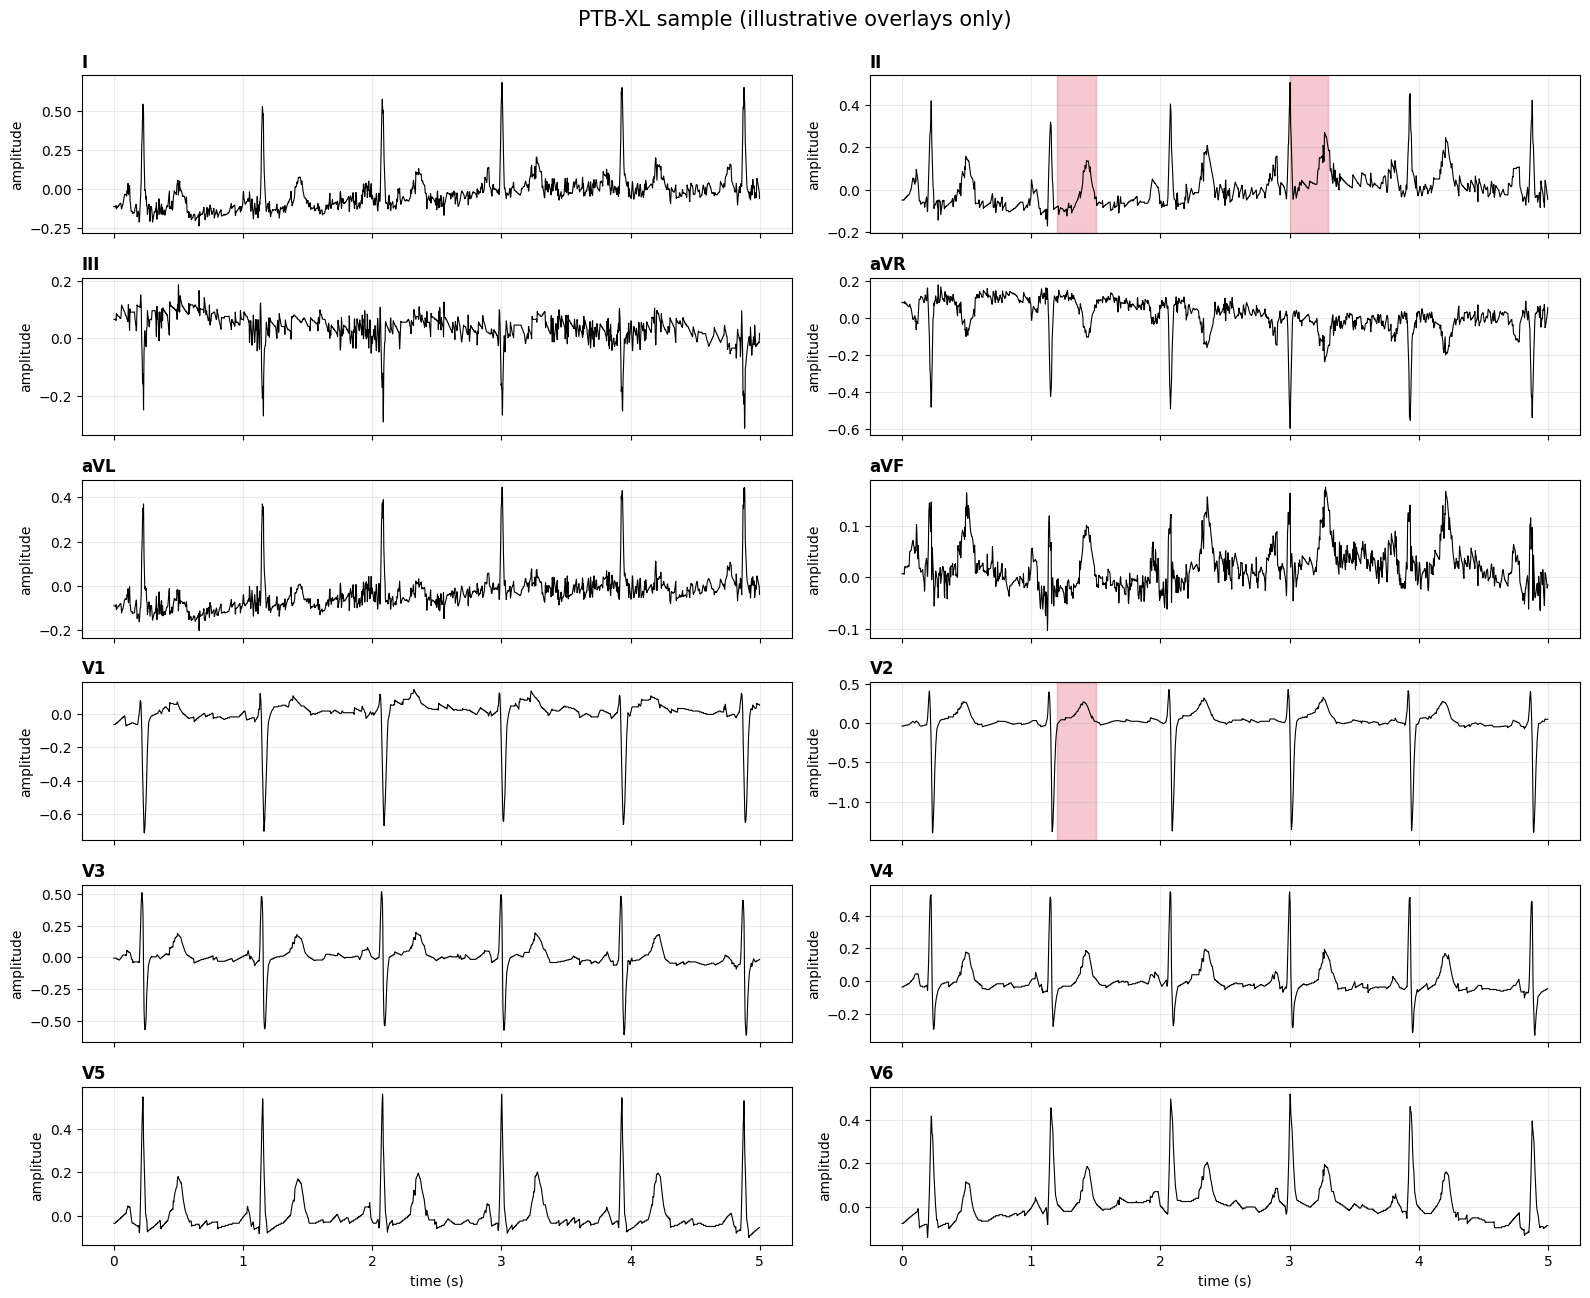

In [7]:
import matplotlib.pyplot as plt

def plot_12lead_ecg(ecg, fs=500, lead_names=ECG_FM_LEADS, regions_by_lead=None, title='12-lead ECG'):
    """Plot (12, time) ECG; overlay transparent spans on requested leads."""
    regions_by_lead = regions_by_lead or {}
    t = np.arange(ecg.shape[1]) / fs
    fig, axes = plt.subplots(6, 2, figsize=(16, 13), sharex=True)
    for ax, lead, y in zip(axes.ravel(), lead_names, ecg):
        ax.plot(t, y, lw=0.8, color='black')
        for start_s, end_s in regions_by_lead.get(lead, []):
            ax.axvspan(start_s, end_s, color='crimson', alpha=0.23, label='selected region')
        ax.set_title(lead, loc='left', fontweight='bold')
        ax.grid(alpha=0.25)
        ax.set_ylabel('amplitude')
    for ax in axes[-1]: ax.set_xlabel('time (s)')
    fig.suptitle(title, y=0.995, fontsize=15)
    fig.tight_layout()
    return fig, axes

# Edit or replace these intervals later with XAI-selected time regions.
demo_regions = {'II': [(1.2, 1.5), (3.0, 3.3)], 'V2': [(1.2, 1.5)]}
plot_12lead_ecg(display_ecg_np, regions_by_lead=demo_regions, title='PTB-XL sample (illustrative overlays only)');

## 7. Load the released pretrained ECG-FM model

The native loader reconstructs the architecture from the checkpoint. Attention extraction is enabled before inference. Model internals can change across framework revisions, so the following code uses defensive inspection rather than assuming a specific attention tensor shape.

In [9]:
!git clone https://github.com/Jwoo5/fairseq-signals.git
%cd fairseq-signals
!pip install -e .

fatal: destination path 'fairseq-signals' already exists and is not an empty directory.
/content/fairseq-signals
Obtaining file:///content/fairseq-signals
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for fairseq_signals (pyproject.toml) ... done
  Created wheel for fairseq_signals: filename=fairseq_signals-1.0.0a0+f8f0ff1-0.editable-cp313-cp313-linux_x86_64.whl size=6634 sha256=7f6724291e7a57cc1e43b990b86a17b1266c711f96d6f658a6061d0ad27cf109
  Stored in directory: /tmp/pip-ephem-wheel-cache-i2r_u224/wheels/f4/82/d5/6a25fc7d41110e9d01841054e2acd53c9ccb2cf18dd87be938
Successfully built fairseq_signals
  Attempting uninstall: fairseq_signals
    Found existing installation: fairseq_signals 1.0.0a0+f8f0ff1
    Uninstalling fairseq_signals-1.0.0a0+f8f0ff1:
      Succes

In [10]:
import torch
from fairseq_signals.models import build_model_from_checkpoint

model = build_model_from_checkpoint(checkpoint_path=checkpoint_path)

# This is the official quickstart's mechanism for exposing layer attention/saliency.
if hasattr(model, 'encoder') and hasattr(model.encoder, 'encoder'):
    transformer = model.encoder.encoder
    if hasattr(transformer, 'need_weights'):
        transformer.need_weights = True
    for layer in getattr(transformer, 'layers', []):
        if hasattr(layer, 'need_weights'):
            layer.need_weights = True

model = model.to(DEVICE).eval()
n_params = sum(p.numel() for p in model.parameters())
print(f'Loaded {type(model).__name__} with {n_params/1e6:.1f}M parameters on {DEVICE}')

Loaded Wav2Vec2CMSCModel with 90.9M parameters on cpu


## 8. Run inference — no retraining

The foundation model's main useful output here is an embedding/representation. If `out` contains logits, their meaning depends on the checkpoint head and must not be interpreted as a diagnosis without the corresponding label definition. The cell prints all available output keys first.

In [11]:
source = torch.from_numpy(model_ecg_np).unsqueeze(0).float().to(DEVICE)  # (batch, 12, 2500)
with torch.inference_mode():
    output = model(source=source)

print('Output keys:', list(output.keys()))
for key, value in output.items():
    if torch.is_tensor(value):
        print(f'{key}: shape={tuple(value.shape)}, dtype={value.dtype}')
    elif isinstance(value, (list, tuple)):
        print(f'{key}: {type(value).__name__}, length={len(value)}')
    else:
        print(f'{key}: {type(value).__name__}')

# Official quickstart pools token/encoder outputs to one vector per example.
if 'encoder_out' in output and torch.is_tensor(output['encoder_out']):
    encoder_out = output['encoder_out']
    embedding = encoder_out.sum(dim=1) / (encoder_out != 0).sum(dim=1).clamp_min(1)
    print('Pooled embedding shape:', tuple(embedding.shape))
else:
    embedding = None
    print('No tensor named encoder_out was returned; inspect output above for this framework revision.')

Output keys: ['x', 'padding_mask', 'features_pen', 'features', 'prob_perplexity', 'code_perplexity', 'num_vars', 'temp']
x: shape=(101, 1, 76), dtype=torch.float32
padding_mask: NoneType
features_pen: shape=(), dtype=torch.float32
features: shape=(1, 156, 768), dtype=torch.float32
prob_perplexity: shape=(), dtype=torch.float32
code_perplexity: shape=(), dtype=torch.float32
num_vars: int
temp: float
No tensor named encoder_out was returned; inspect output above for this framework revision.


## 9. Attention / feature-importance scaffold

Attention is not automatically a causal explanation. Treat it as a visualization signal, compare it to gradient methods and clinician review, and do not convert it into a clinical conclusion. The official finetuned-model quickstart exposes `output['saliency']`; this cell safely checks whether the selected checkpoint/framework combination returned it and maps one-dimensional token importance to time for an illustrative lead plot.

In [12]:
def normalize_01(x):
    x = np.asarray(x, dtype=float)
    return (x - x.min()) / (x.max() - x.min() + 1e-12)

def token_importance_to_sample_importance(token_importance, n_samples=2500):
    """Linearly map one importance value per model token back to ECG samples."""
    token_importance = np.asarray(token_importance).reshape(-1)
    return np.interp(np.linspace(0, len(token_importance)-1, n_samples),
                     np.arange(len(token_importance)), normalize_01(token_importance))

attention_sample_importance = None
if 'saliency' in output and torch.is_tensor(output['saliency']):
    saliency = output['saliency'].detach().float().cpu()
    print('Raw saliency shape:', tuple(saliency.shape))
    # Common author-quickstart form: (batch, layers, tokens, tokens).
    if saliency.ndim == 4:
        token_importance = saliency[0, -1].amax(dim=-1).numpy()
        attention_sample_importance = token_importance_to_sample_importance(token_importance)
    else:
        print('Saliency shape differs from the documented example; inspect it before reducing axes.')
else:
    print('No output["saliency"] tensor. This can occur with the pretrained checkpoint. See the hook scaffold below or use the released finetuned checkpoint for the official saliency path.')

if attention_sample_importance is not None:
    lead = 'II'; lead_idx = ECG_FM_LEADS.index(lead); t = np.arange(N_SAMPLES) / TARGET_FS
    fig, ax = plt.subplots(figsize=(15, 3))
    ax.plot(t, display_ecg_np[lead_idx], color='black', lw=0.8)
    ax.scatter(t, display_ecg_np[lead_idx], c=attention_sample_importance, s=3, cmap='magma')
    ax.set(title=f'{lead}: attention-derived token importance (exploratory)', xlabel='time (s)')
    plt.show()

No output["saliency"] tensor. This can occur with the pretrained checkpoint. See the hook scaffold below or use the released finetuned checkpoint for the official saliency path.


In [13]:
# Optional: generic forward-hook collector for model feature maps.
# Choose a specific named module only after printing model.named_modules().
# This avoids silently attaching a hook to the wrong layer after framework updates.
for name, module in list(model.named_modules())[-25:]:
    print(name, '->', type(module).__name__)

# Example pattern (uncomment AFTER replacing TARGET_MODULE_NAME):
# captured = {}
# def save_output(module, inputs, output):
#     captured['features'] = output.detach().cpu() if torch.is_tensor(output) else output
# target_module = dict(model.named_modules())['TARGET_MODULE_NAME']
# hook_handle = target_module.register_forward_hook(save_output)
# with torch.inference_mode(): _ = model(source=source)
# hook_handle.remove()
# print(type(captured.get('features')))

feature_extractor.conv_layers.1.0 -> Conv1d
feature_extractor.conv_layers.1.1 -> Dropout
feature_extractor.conv_layers.1.2 -> GELU
feature_extractor.conv_layers.2 -> Sequential
feature_extractor.conv_layers.2.0 -> Conv1d
feature_extractor.conv_layers.2.1 -> Dropout
feature_extractor.conv_layers.2.2 -> GELU
feature_extractor.conv_layers.3 -> Sequential
feature_extractor.conv_layers.3.0 -> Conv1d
feature_extractor.conv_layers.3.1 -> Dropout
feature_extractor.conv_layers.3.2 -> GELU
post_extract_proj -> Linear
conv_pos -> ConvPositionalEncoding
conv_pos.pos_conv -> Sequential
conv_pos.pos_conv.0 -> ParametrizedConv1d
conv_pos.pos_conv.0.parametrizations -> ModuleDict
conv_pos.pos_conv.0.parametrizations.weight -> ParametrizationList
conv_pos.pos_conv.0.parametrizations.weight.0 -> _WeightNorm
conv_pos.pos_conv.1 -> SamePad
conv_pos.pos_conv.2 -> GELU
layer_norm -> LayerNorm
quantizer -> GumbelVectorQuantizer
quantizer.weight_proj -> Linear
project_q -> Linear
final_proj -> Linear


## 10. Gradient-based XAI scaffold for a future classifier head

Integrated Gradients, Saliency, and DeepLIFT need a **differentiable scalar target**. For the pretrained checkpoint, attach/train a validated downstream head first; then replace `forward_target` below with a function returning the logit for a documented target class. Do not run attribution against a probability after sigmoid: use the raw logit. Baseline choice, completeness checks, and stability across preprocessing choices are part of the evaluation—not afterthoughts.

In [14]:
# Scaffold only: it raises until a real, validated target head is supplied.
from captum.attr import IntegratedGradients, Saliency, DeepLift

def forward_target(x):
    """
    Replace with a scalar raw logit per input, e.g. model_with_head(x)[:, TARGET_INDEX].
    The output shape must be (batch,), not an embedding or post-sigmoid probability.
    """
    raise NotImplementedError('Attach a validated task head and return its raw target logit here.')

def compute_attributions(x, method='integrated_gradients', baseline=None):
    x = x.detach().clone().requires_grad_(True)
    baseline = torch.zeros_like(x) if baseline is None else baseline.to(x.device)
    methods = {
        'integrated_gradients': IntegratedGradients(forward_target),
        'saliency': Saliency(forward_target),
        'deeplift': DeepLift(forward_target),
    }
    if method not in methods: raise ValueError(f'Choose one of {list(methods)}')
    if method == 'integrated_gradients':
        attr, delta = methods[method].attribute(x, baselines=baseline, n_steps=64, return_convergence_delta=True)
        print('IG completeness delta:', delta.detach().cpu().numpy())
    elif method == 'deeplift':
        attr = methods[method].attribute(x, baselines=baseline)
    else:
        attr = methods[method].attribute(x)
    return attr.detach().cpu().numpy()

# After defining a validated head, use e.g.:
# attribution = compute_attributions(source, method='integrated_gradients')  # (1, 12, 2500)
# per_lead_time_importance = np.abs(attribution[0])
# Then derive thresholded contiguous intervals and pass them to plot_12lead_ecg(...).

## 11. Convert a per-lead importance map into highlight regions

This helper turns a `(12, 2500)` XAI map into contiguous time spans. It is deliberately a transparent thresholding rule, not an automatic clinical interpretation. Try several thresholds and check sensitivity.

{'II': [(np.float64(1.2), np.float64(1.52))]}


(<Figure size 1600x1300 with 12 Axes>,
 array([[<Axes: title={'left': 'I'}, ylabel='amplitude'>,
         <Axes: title={'left': 'II'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'III'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVR'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'aVL'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVF'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V1'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V2'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V3'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V4'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V5'}, xlabel='time (s)', ylabel='amplitude'>,
         <Axes: title={'left': 'V6'}, xlabel='time (s)', ylabel='amplitude'>]],
       dtype=object))

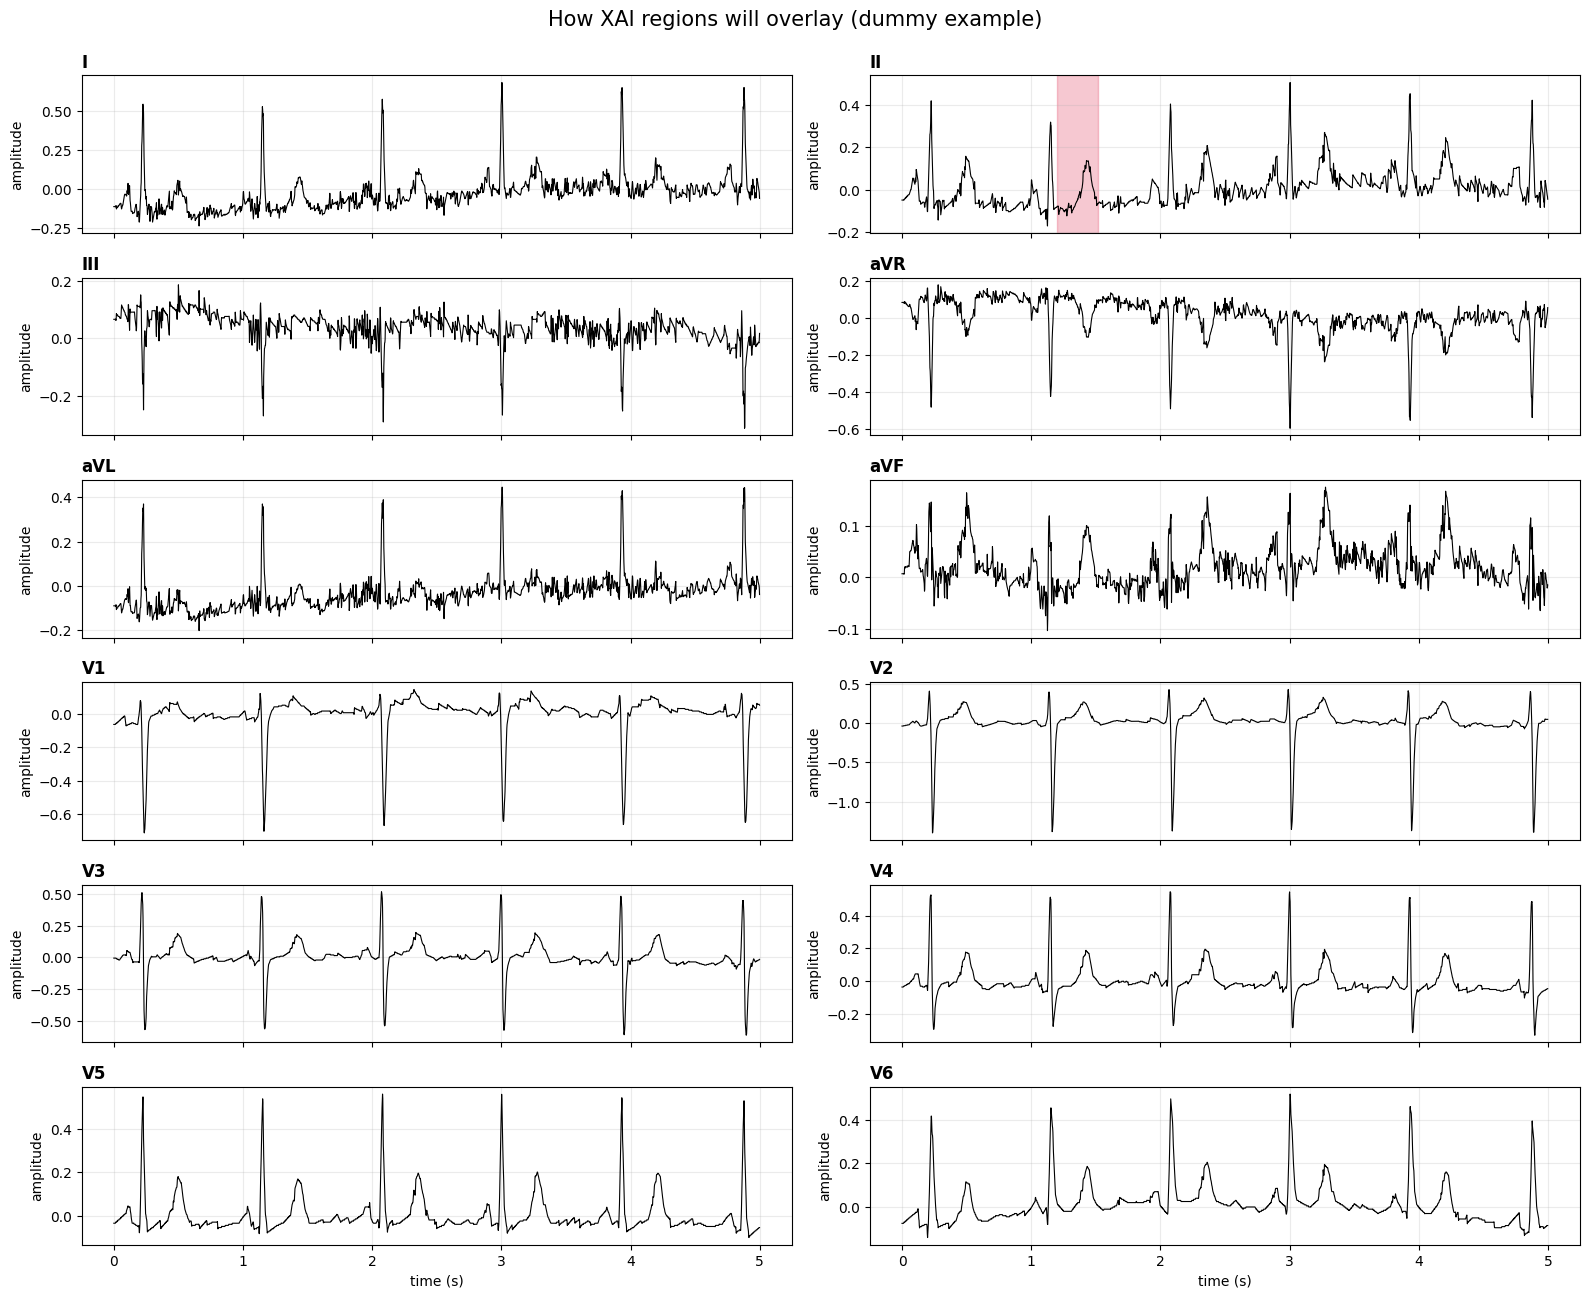

In [16]:
def importance_to_regions(importance, percentile=95, fs=500, min_duration_s=0.02):
    imp = np.abs(np.asarray(importance))

    if imp.shape[0] != len(ECG_FM_LEADS):
        raise ValueError(f'Expected {len(ECG_FM_LEADS)} leads, got {imp.shape}')

    # ใช้เฉพาะค่าที่ > 0 หา threshold
    nonzero = imp[imp > 0]

    if len(nonzero) == 0:
        return {}

    threshold = np.percentile(nonzero, percentile)

    min_samples = max(1, round(min_duration_s * fs))
    result = {}

    for lead, values in zip(ECG_FM_LEADS, imp):
        # สำคัญ: ต้อง > 0 ด้วย
        mask = (values >= threshold) & (values > 0)

        edges = np.diff(
            np.r_[False, mask, False].astype(np.int8)
        )

        starts = np.where(edges == 1)[0]
        ends = np.where(edges == -1)[0]

        spans = [
            (s / fs, e / fs)
            for s, e in zip(starts, ends)
            if e - s >= min_samples
        ]

        if spans:
            result[lead] = spans

    return result


# Dummy test
dummy_importance = np.zeros((12, N_SAMPLES))

# Lead II, sample 600–760
dummy_importance[1, 600:760] = 1.0

highlight_regions = importance_to_regions(
    dummy_importance,
    percentile=95
)

print(highlight_regions)

plot_12lead_ecg(
    display_ecg_np,
    regions_by_lead=highlight_regions,
    title='How XAI regions will overlay (dummy example)'
)

In [19]:

model_for_xai = model

model_for_xai.eval()

print("XAI model ready:", type(model_for_xai))

XAI model ready: <class 'fairseq_signals.models.wav2vec2.wav2vec2_cmsc.Wav2Vec2CMSCModel'>


In [27]:

from fairseq_signals.utils.utils import buffered_arange

if hasattr(buffered_arange, "buf"):
    delattr(buffered_arange, "buf")

print("buffered_arange cache reset ")

buffered_arange cache reset 


In [28]:
test_out = model(source=source)

print(type(test_out))

if isinstance(test_out, dict):
    print(test_out.keys())

    for k, v in test_out.items():
        if torch.is_tensor(v):
            print(k, v.shape)

<class 'dict'>
dict_keys(['x', 'padding_mask', 'features_pen', 'features', 'prob_perplexity', 'code_perplexity', 'num_vars', 'temp'])
x torch.Size([101, 1, 88])
features_pen torch.Size([])
features torch.Size([1, 156, 768])
prob_perplexity torch.Size([])
code_perplexity torch.Size([])


In [29]:
# Prepare ECG input for XAI
x = source.clone().detach().requires_grad_(True)

# Important: normal forward pass, NOT inference_mode()
test_out = model(source=x)

print(type(test_out))

if isinstance(test_out, dict):
    print("Output keys:", test_out.keys())

    for k, v in test_out.items():
        if torch.is_tensor(v):
            print(k, tuple(v.shape))

<class 'dict'>
Output keys: dict_keys(['x', 'padding_mask', 'features_pen', 'features', 'prob_perplexity', 'code_perplexity', 'num_vars', 'temp'])
x (101, 1, 64)
features_pen ()
features (1, 156, 768)
prob_perplexity ()
code_perplexity ()


In [30]:
import torch
import torch.nn as nn

class ECGFMFeatureTarget(nn.Module):
    def __init__(self, model):
        super().__init__()
        self.model = model

    def forward(self, x):
        out = self.model(source=x)

        features = out["features"]   # [B, 156, 768]

        # scalar ต่อ sample
        score = features.abs().mean(dim=(1, 2))

        return score

model_for_xai = ECGFMFeatureTarget(model)
model_for_xai.eval()

ECGFMFeatureTarget(
  (model): Wav2Vec2CMSCModel(
    (dropout_input): Dropout(p=0.1, inplace=False)
    (dropout_features): Dropout(p=0.1, inplace=False)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiHeadAttention(
            (dropout): Dropout()
            (k_proj): Linear(in_features=768, out_features=768, bias=True)
            (v_proj): Linear(in_features=768, out_features=768, bias=True)
            (q_proj): Linear(in_features=768, out_features=768, bias=True)
            (out_proj): Linear(in_features=768, out_features=768, bias=True)
          )
          (dropout1): Dropout(p=0.1, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
          (dropout3): Dropout(p=0.1, inplace=False)
          (self_attn_layer_norm): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
          (fc1): Linear(in_features=768, out_features=3072, bias=True)
          (fc2): Linear(in_feat

Saliency / Vanilla Gradient

(<Figure size 1600x1300 with 12 Axes>,
 array([[<Axes: title={'left': 'I'}, ylabel='amplitude'>,
         <Axes: title={'left': 'II'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'III'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVR'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'aVL'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVF'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V1'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V2'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V3'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V4'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V5'}, xlabel='time (s)', ylabel='amplitude'>,
         <Axes: title={'left': 'V6'}, xlabel='time (s)', ylabel='amplitude'>]],
       dtype=object))

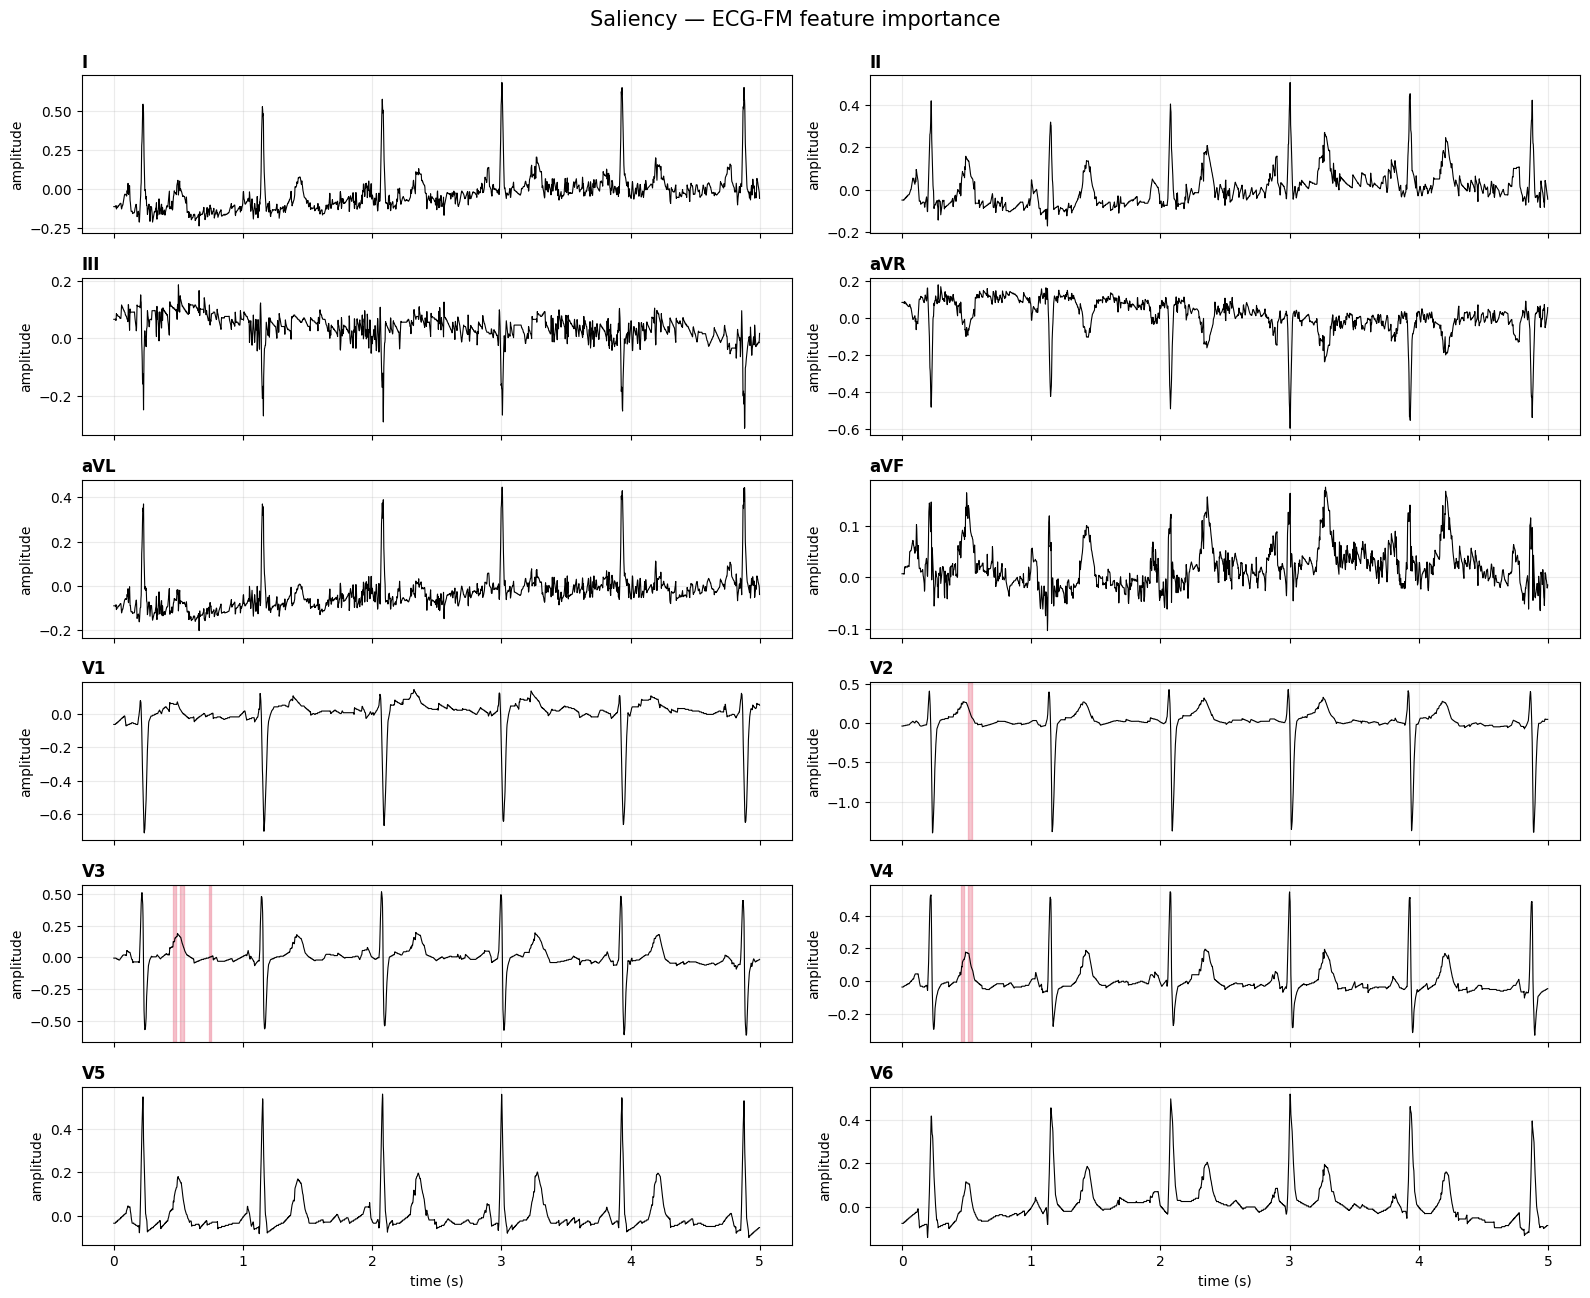

In [31]:
from captum.attr import Saliency

x = source.clone().detach().requires_grad_(True)

saliency = Saliency(model_for_xai)

attr = saliency.attribute(x)

importance_saliency = (
    attr.abs()
        .detach()
        .cpu()
        .numpy()[0]
)

regions_saliency = importance_to_regions(
    importance_saliency,
    percentile=95
)

plot_12lead_ecg(
    display_ecg_np,
    regions_by_lead=regions_saliency,
    title="Saliency — ECG-FM feature importance"
)

Integrated Gradients

(<Figure size 1600x1300 with 12 Axes>,
 array([[<Axes: title={'left': 'I'}, ylabel='amplitude'>,
         <Axes: title={'left': 'II'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'III'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVR'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'aVL'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVF'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V1'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V2'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V3'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V4'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V5'}, xlabel='time (s)', ylabel='amplitude'>,
         <Axes: title={'left': 'V6'}, xlabel='time (s)', ylabel='amplitude'>]],
       dtype=object))

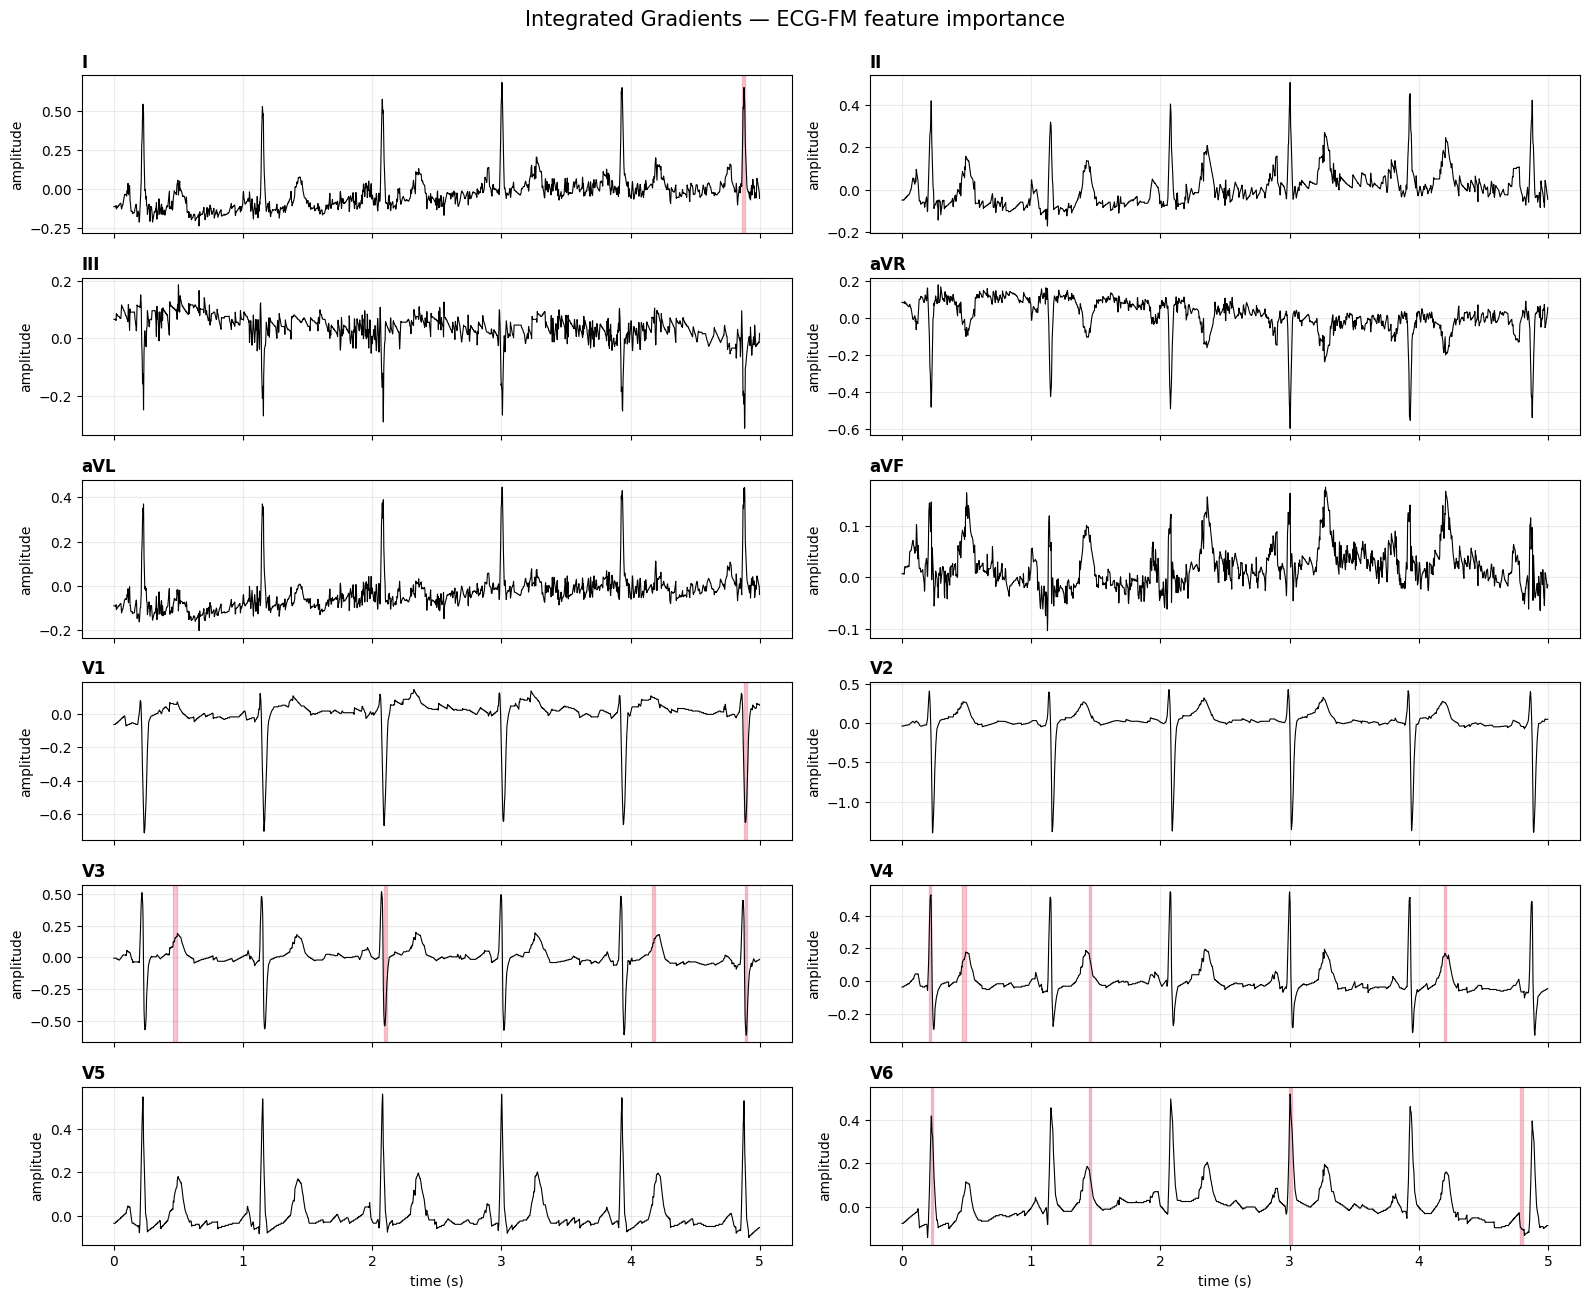

In [32]:
from captum.attr import IntegratedGradients

ig = IntegratedGradients(model_for_xai)

attr_ig = ig.attribute(
    source,
    baselines=torch.zeros_like(source),
    n_steps=32
)

importance_ig = attr_ig.abs().detach().cpu().numpy()[0]

regions_ig = importance_to_regions(
    importance_ig,
    percentile=95
)

plot_12lead_ecg(
    display_ecg_np,
    regions_by_lead=regions_ig,
    title="Integrated Gradients — ECG-FM feature importance"
)

DeepLIFT

/usr/local/lib/python3.13/dist-packages/captum/log/dummy_log.py:54: UserWarning: Setting forward, backward hooks and attributes on non-linear
               activations. The hooks and attributes will be removed
            after the attribution is finished
  return func(*args, **kwargs)


DeepLIFT regions:
{'II': [(np.float64(3.92), np.float64(3.946))], 'V1': [(np.float64(3.928), np.float64(3.95)), (np.float64(4.88), np.float64(4.906))], 'V2': [(np.float64(4.882), np.float64(4.902))], 'V3': [(np.float64(3.02), np.float64(3.042)), (np.float64(4.886), np.float64(4.914))], 'V4': [(np.float64(2.348), np.float64(2.368))], 'V5': [(np.float64(1.134), np.float64(1.154)), (np.float64(2.336), np.float64(2.364)), (np.float64(2.998), np.float64(3.02)), (np.float64(3.918), np.float64(3.948)), (np.float64(4.86), np.float64(4.88))], 'V6': [(np.float64(2.99), np.float64(3.022)), (np.float64(4.84), np.float64(4.86))]}


(<Figure size 1600x1300 with 12 Axes>,
 array([[<Axes: title={'left': 'I'}, ylabel='amplitude'>,
         <Axes: title={'left': 'II'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'III'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVR'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'aVL'}, ylabel='amplitude'>,
         <Axes: title={'left': 'aVF'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V1'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V2'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V3'}, ylabel='amplitude'>,
         <Axes: title={'left': 'V4'}, ylabel='amplitude'>],
        [<Axes: title={'left': 'V5'}, xlabel='time (s)', ylabel='amplitude'>,
         <Axes: title={'left': 'V6'}, xlabel='time (s)', ylabel='amplitude'>]],
       dtype=object))

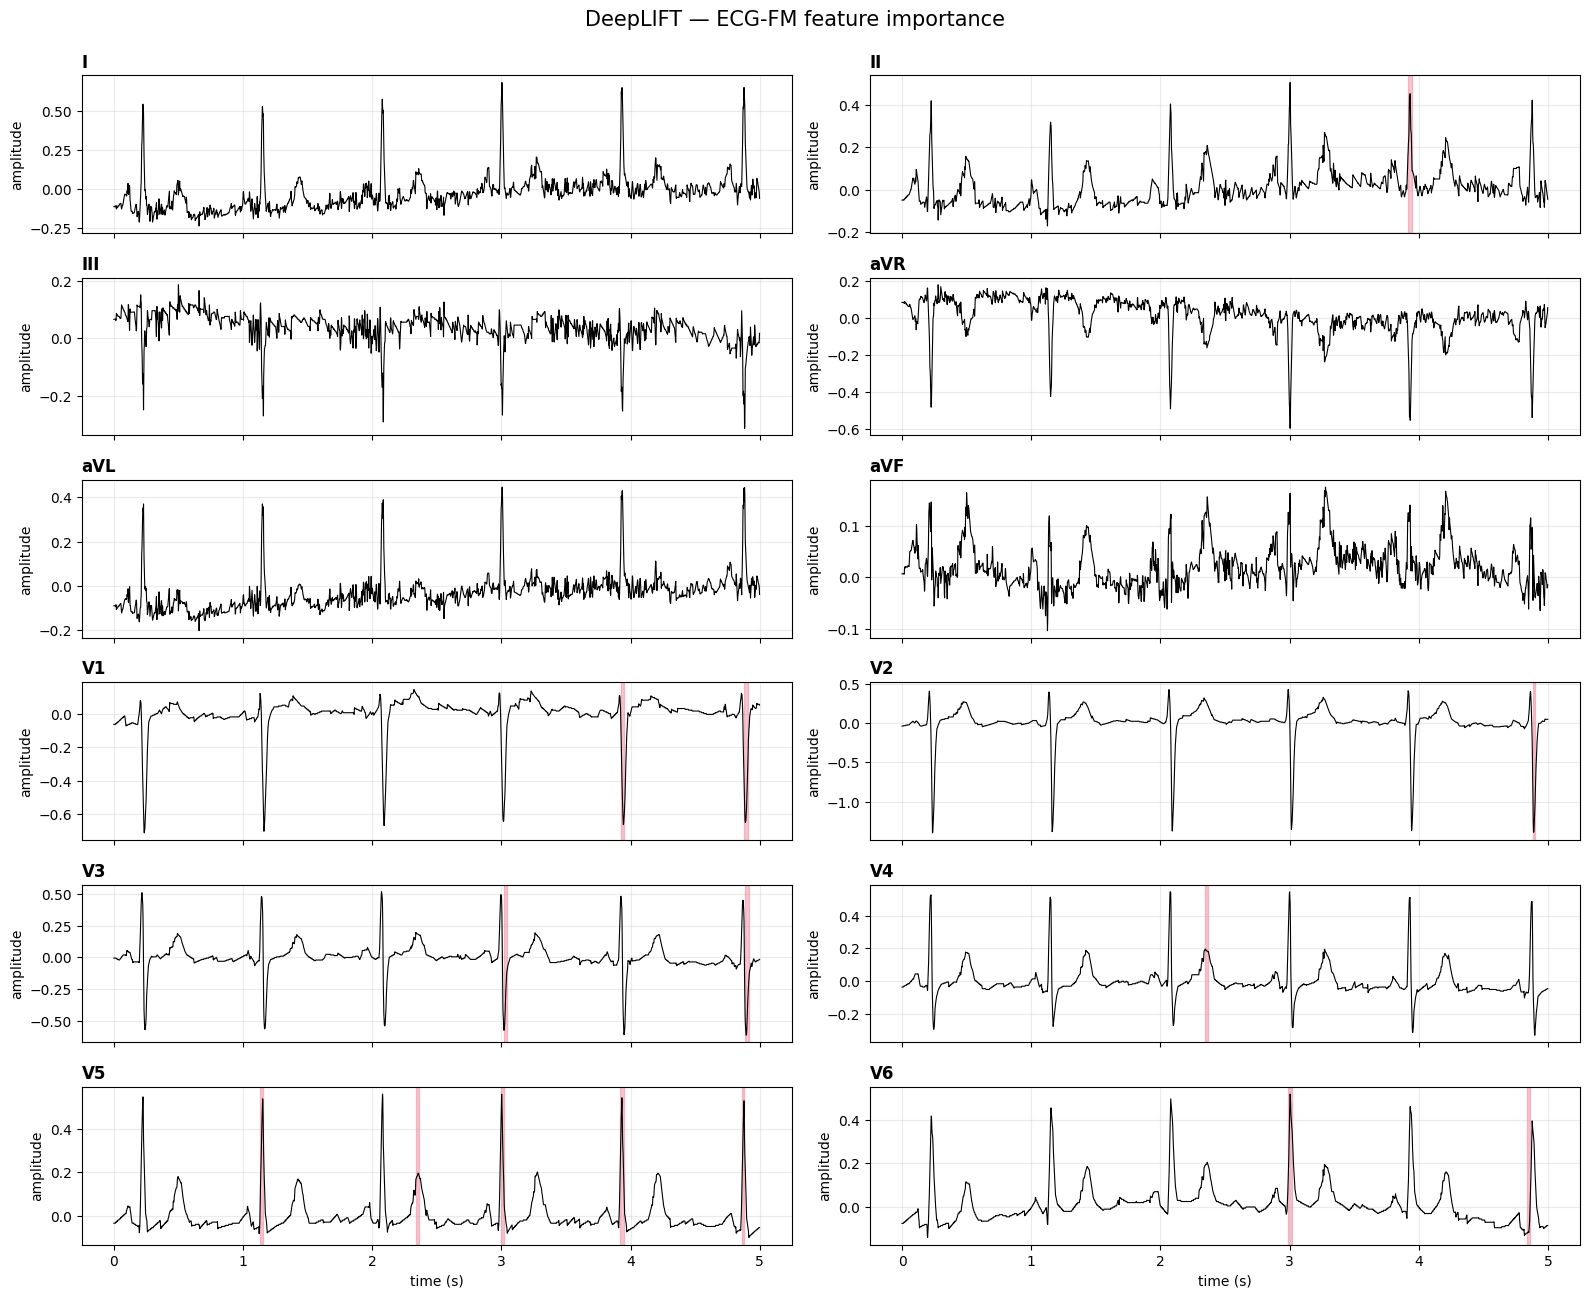

In [33]:
# ==============================
# XAI 3: DeepLIFT
# ==============================

import torch
import numpy as np
from captum.attr import DeepLift

model_for_xai.eval()

x = source.clone().detach().requires_grad_(True)
baseline = torch.zeros_like(x)

deeplift = DeepLift(model_for_xai)

attr_dl = deeplift.attribute(
    x,
    baselines=baseline
)

importance_dl = (
    attr_dl
    .abs()
    .detach()
    .cpu()
    .numpy()[0]
)

regions_dl = importance_to_regions(
    importance_dl,
    percentile=95
)

print("DeepLIFT regions:")
print(regions_dl)

plot_12lead_ecg(
    display_ecg_np,
    regions_by_lead=regions_dl,
    title="DeepLIFT — ECG-FM feature importance"
)

1D Grad-CAM

Conv1d layers found:
0 feature_extractor.conv_layers.0.0 Conv1d(12, 256, kernel_size=(2,), stride=(2,), bias=False)
1 feature_extractor.conv_layers.1.0 Conv1d(256, 256, kernel_size=(2,), stride=(2,), bias=False)
2 feature_extractor.conv_layers.2.0 Conv1d(256, 256, kernel_size=(2,), stride=(2,), bias=False)
3 feature_extractor.conv_layers.3.0 Conv1d(256, 256, kernel_size=(2,), stride=(2,), bias=False)
4 conv_pos.pos_conv.0 ParametrizedConv1d(
  768, 768, kernel_size=(128,), stride=(1,), padding=(64,), groups=16
  (parametrizations): ModuleDict(
    (weight): ParametrizationList(
      (0): _WeightNorm()
    )
  )
)

Using Grad-CAM layer:
conv_pos.pos_conv.0
Activation shape: torch.Size([1, 768, 157])
Gradient shape: torch.Size([1, 768, 157])

1D Grad-CAM regions:
{'I': [(np.float64(2.772), np.float64(2.808)), (np.float64(2.826), np.float64(2.868))], 'II': [(np.float64(2.772), np.float64(2.808)), (np.float64(2.826), np.float64(2.868))], 'III': [(np.float64(2.772), np.float64(2.808)), (np

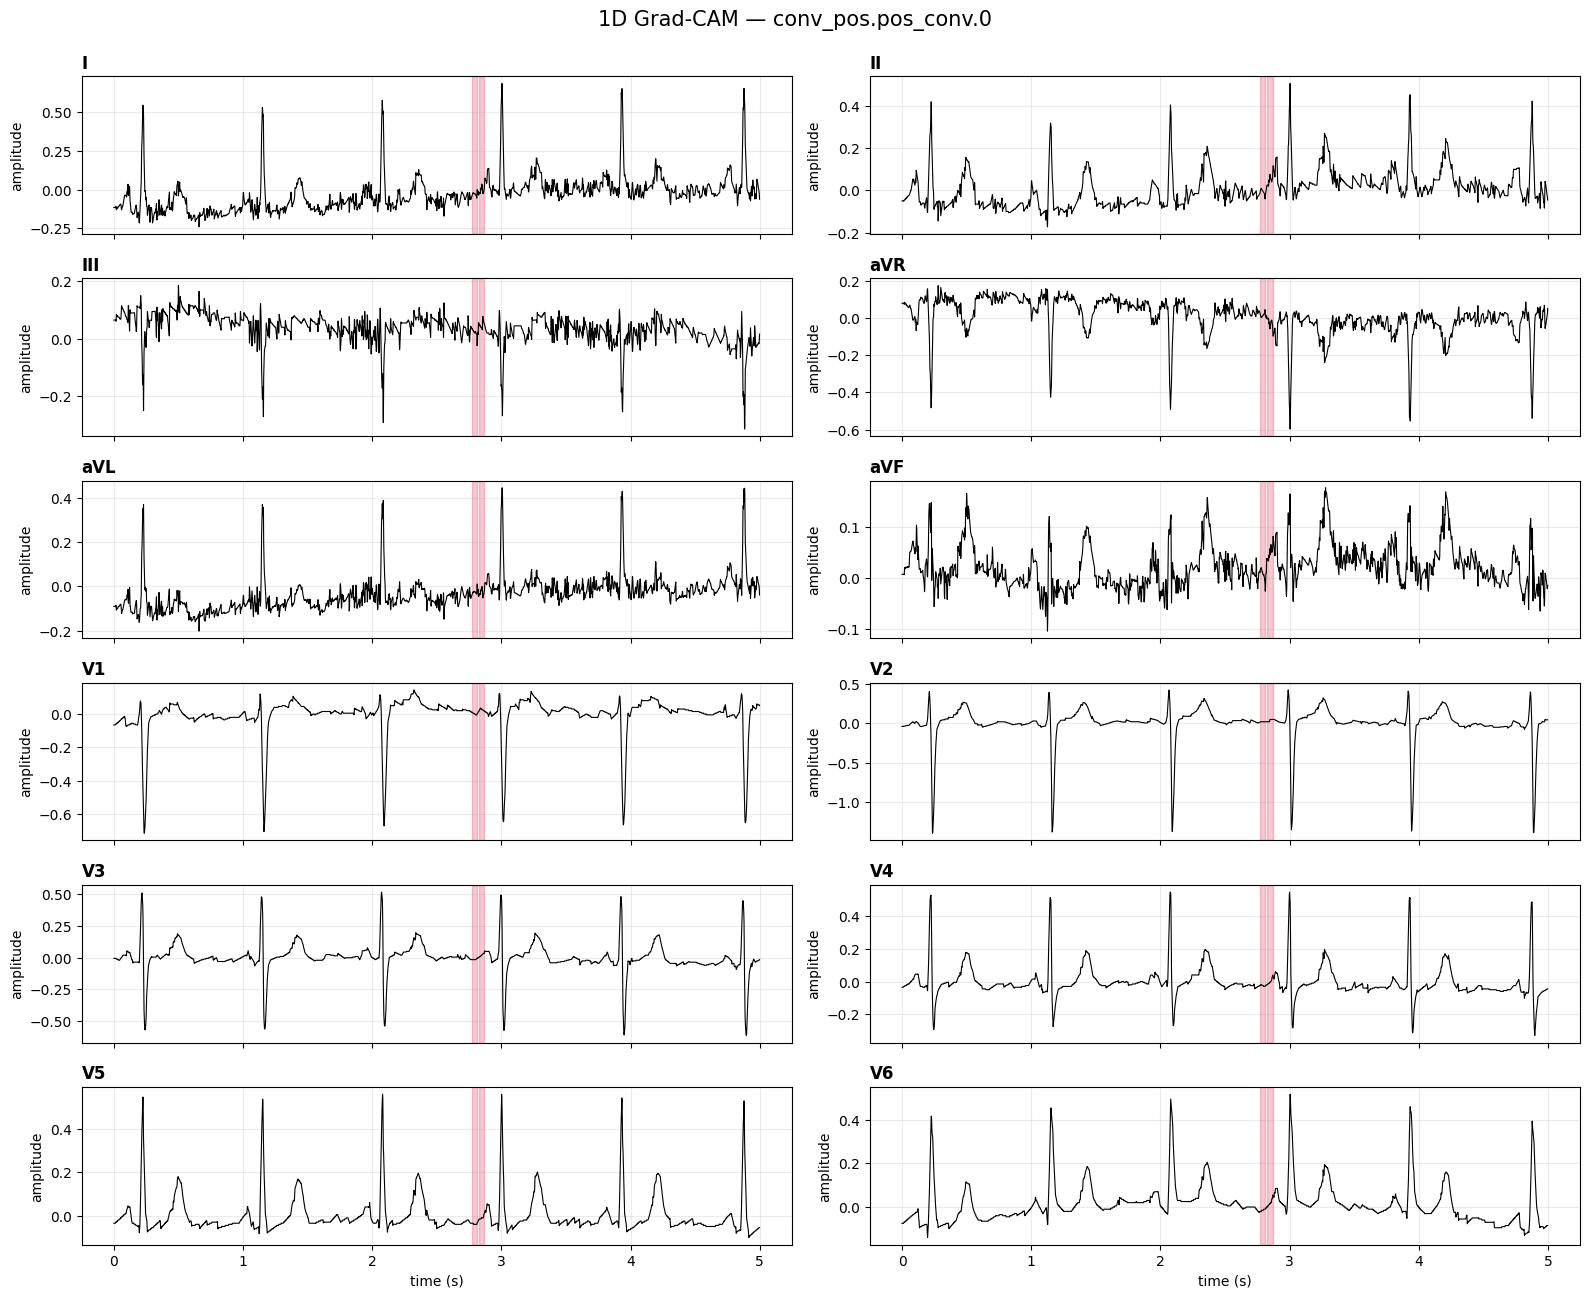

In [34]:
# ==============================
# XAI 4: 1D Grad-CAM
# ==============================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

model.eval()

# หา Conv1d layers ทั้งหมด
conv_layers = []

for name, module in model.named_modules():
    if isinstance(module, nn.Conv1d):
        conv_layers.append((name, module))

print("Conv1d layers found:")
for i, (name, layer) in enumerate(conv_layers):
    print(i, name, layer)

if len(conv_layers) == 0:
    raise RuntimeError("No Conv1d layer found in ECG-FM")

# ใช้ Conv1d ตัวสุดท้าย
target_layer_name, target_layer = conv_layers[-1]

print("\nUsing Grad-CAM layer:")
print(target_layer_name)

activations = {}
gradients = {}

def forward_hook(module, inputs, output):
    activations["value"] = output

def backward_hook(module, grad_input, grad_output):
    gradients["value"] = grad_output[0]

h1 = target_layer.register_forward_hook(forward_hook)
h2 = target_layer.register_full_backward_hook(backward_hook)

# reset fairseq_signals cache เผื่อเคยใช้ inference_mode มาก่อน
from fairseq_signals.utils.utils import buffered_arange

if hasattr(buffered_arange, "buf"):
    delattr(buffered_arange, "buf")

x = source.clone().detach().requires_grad_(True)

model.zero_grad()

out = model(source=x)

# ใช้ foundation representation เป็น scalar target ชั่วคราว
features = out["features"]      # [B, tokens, hidden]
score = features.abs().mean()

score.backward()

acts = activations["value"]
grads = gradients["value"]

print("Activation shape:", acts.shape)
print("Gradient shape:", grads.shape)

# Grad-CAM weighting
weights = grads.mean(dim=-1, keepdim=True)

cam = (weights * acts).sum(dim=1)
cam = torch.relu(cam)

# normalize
cam = cam - cam.min(dim=-1, keepdim=True).values
cam = cam / (cam.max(dim=-1, keepdim=True).values + 1e-8)

# upsample กลับไป ECG sample length
T = source.shape[-1]

cam_up = F.interpolate(
    cam.unsqueeze(1),
    size=T,
    mode="linear",
    align_corners=False
).squeeze(1)

cam_np = cam_up.detach().cpu().numpy()[0]

# Grad-CAM นี้ได้ temporal importance อย่างเดียว
# จึง broadcast เหมือนกันทุก lead เพื่อ visualization
importance_gradcam = np.tile(
    cam_np[None, :],
    (12, 1)
)

regions_gradcam = importance_to_regions(
    importance_gradcam,
    percentile=95
)

print("\n1D Grad-CAM regions:")
print(regions_gradcam)

plot_12lead_ecg(
    display_ecg_np,
    regions_by_lead=regions_gradcam,
    title=f"1D Grad-CAM — {target_layer_name}"
)

h1.remove()
h2.remove()